# KO3 — AlphaMissense Provides Greater Diagnostic Value Than BLOSUM62

## Overview

This notebook tests **Key Objective 3**: whether AlphaMissense (AM) pathogenicity scores provide greater diagnostic value than BLOSUM62 substitution scores for distinguishing PDAC (somatic) mutations from healthy (germline) mutations. It reproduces the BLOSUM62-based overall score distribution, gene-level pathogenicity categorisation, and driver-gene distribution analyses from `09_BLOSUM.ipynb`, directly contrasting them — in text and in a shared effect-size table — with the AM-based results established in `KO1_AM_somatic_vs_germline.ipynb` and `KO2_AM_driver_genes.ipynb`. The notebook produces three BLOSUM62 figures — overall score distribution, pathogenic gene shares (gene-level median), and driver-gene distributions — plus a genome-wide and per-driver-gene CLES comparison table for both predictors, together demonstrating that AM separates PDAC from healthy far more clearly than BLOSUM62 (CLES ≈ 83% vs ≈ 55%) and identifies more, and more cleanly separated, pathogenic genes.

## Data

**Input**
- `../Data/merged_tcga_1000G.parquet` — same merged somatic+germline mutation table as KO1/KO2 (`source == 'TCGA'` somatic vs `source == '1000G'` germline).
  Columns used: `source`, `gene_name`, `sample_id`, `blosum62_score`, `am_pathogenicity`.

**Processing**
- Split the merged table into `tcga` (somatic) and `g1000` (germline) by `source`.
- Compute the overall BLOSUM62 score distribution (PDAC vs Healthy).
- Categorise genes by their **median** BLOSUM62 score against BLOSUM62's pathogenicity thresholds, for the pathogenic-gene-share figure (compared in text against AlphaMissense's KO1 result).
- Compute per-driver-gene BLOSUM62 score distributions for KRAS, TP53, SMAD4, CDKN2A.
- Compute direction-aware Common Language Effect Size (CLES) and its conservative 95% lower bound (CLES_LB) for both predictors, genome-wide and per driver gene.

**Output**
- `../Figures/KO3_blosum_score_distribution.png` / `.pdf` — Figure 1 (overall BLOSUM62 distribution)
- `../Figures/KO3_pathogenic_gene_share_comparison.png` / `.pdf` — Figure 2 (BLOSUM62 pathogenic-gene shares, gene-level median)
- `../Figures/KO3_driver_gene_distributions.png` / `.pdf` — Figure 3 (driver-gene BLOSUM62 distributions)
- An inline-rendered CLES comparison table (Paragraph 5; not exported as an image)

## Method

- **BLOSUM62 thresholds** (inverted relative to AlphaMissense — *lower* score is more pathogenic): pathogenic ≤ –2, uncertain –1…1, benign ≥ 2 (`BL_PATH_MAX = -2`, `BL_BENIGN_MIN = 2`).
- **Overall distribution**: integer-binned bar chart with fitted normal curves and group means, for PDAC vs Healthy BLOSUM62 scores.
- **Gene-level pathogenicity categorisation**: each gene is classified by its **median** BLOSUM62 score against BLOSUM62's thresholds, then tallied into benign / uncertain / pathogenic shares — identical logic to KO1's Figure 2 (which used AlphaMissense), enabling a direct numerical comparison between the two predictors.
- **Driver-gene distributions**: 2×2 grid of integer bar chart + smoothed KDE overlay per gene (KRAS, TP53, SMAD4, CDKN2A), inverted x-axis (benign left, pathogenic right) to match BLOSUM62's reversed pathogenicity direction.
- **Common Language Effect Size (CLES)**: direction-aware Mann-Whitney-U-based estimate of P[PDAC mutation more pathogenic than Healthy mutation] — for BLOSUM62 (lower = more pathogenic) CLES = P[PDAC < Healthy]; for AlphaMissense (higher = more pathogenic) CLES = P[PDAC > Healthy] — computed genome-wide ("Overall") and per canonical driver gene, with conservative 95% CI lower bounds (CLES_LB).

## Content

| # | Name | Description |
|---|------|-------------|
| 1 | Setup & Data Loading | Imports, plotting style, BLOSUM62 thresholds & colour constants (incl. `DRIVER_GENES`), load `merged_tcga_1000G.parquet`, split into PDAC/Healthy, set up the figure output directory |
| 2 | Figure 1 — Overall BLOSUM62 Score Distribution | Bar chart + fitted normal curves of BLOSUM62 scores for PDAC vs Healthy, showing the two distributions barely differ; saved as `KO3_blosum_score_distribution.{png,pdf}` |
| 3 | Figure 2 — Pathogenic Gene Shares (BLOSUM62, Gene-Level Median) | Stacked-bar chart of gene-level pathogenicity shares for PDAC vs Healthy, categorised by median BLOSUM62 score ("Analysis 4b"); shows BLOSUM62 finds fewer pathogenic genes and barely separates PDAC from Healthy (22.2% vs 15.6%) compared with AlphaMissense (KO1: 25.9% vs 3.1%); saved as `KO3_pathogenic_gene_share_comparison.{png,pdf}` |
| 4 | Figure 3 — Driver Gene BLOSUM62 Score Distributions | Combined 2×2 distribution plot for KRAS/TP53/SMAD4/CDKN2A showing diffuse, heavily-overlapping BLOSUM62 score distributions between PDAC and Healthy; saved as `KO3_driver_gene_distributions.{png,pdf}` |
| 5 | Table — AlphaMissense vs BLOSUM62 Effect Size Comparison | Styled comparison table (CLES & CLES_LB, both predictors side by side) for "Overall" + the 4 driver genes, showing genome-wide CLES ≈ 83% (AM) vs ≈ 55% (BLOSUM62) |

## 1. Setup & Data Loading

In [1]:
import pathlib
import polars as pl
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import gaussian_kde, mannwhitneyu
from great_tables import GT, md, style, loc
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
sns.set_theme(style='whitegrid', context='paper', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 130})

In [3]:
COLOR_PDAC      = '#E69F00'   # orange    — TCGA / PDAC  (Wong palette)
COLOR_HEALTHY   = '#56B4E9'   # sky-blue  — 1000G / Healthy
COLOR_BENIGN    = '#2065ab'   # RdBu_r 0.10 — benign
COLOR_UNCERTAIN = '#b1d5e7'   # RdBu_r 0.35 — uncertain
COLOR_PATH      = '#b1182b'   # RdBu_r 0.90 — pathogenic

DRIVER_GENES = ['KRAS', 'TP53', 'SMAD4', 'CDKN2A']

# BLOSUM62: lower score = more pathogenic (inverted relative to AlphaMissense)
BL_PATH_MAX   = -2    # pathogenic: BLOSUM62 <= -2
BL_BENIGN_MIN =  2    # benign:     BLOSUM62 >= 2
BL_X_MIN      = -5    # plot x-axis lower limit
BL_X_MAX      =  4    # plot x-axis upper limit

# DATA_PATH = 'C:/2604_BRP/Data/merged_tcga_1000G.parquet'   # coworker path
DATA_PATH = 'C:/Users/daane/Desktop/DATA/merged_tcga_1000G.parquet'

In [4]:
df = (
    pl.read_parquet(DATA_PATH)
    .select(['source', 'gene_name', 'sample_id', 'blosum62_score', 'am_pathogenicity'])
)
tcga  = df.filter(pl.col('source') == 'TCGA')
g1000 = df.filter(pl.col('source') == '1000G')

print(f'TCGA rows : {len(tcga):,}')
print(f'1000G rows: {len(g1000):,}')

out_dir = pathlib.Path('../Figures')
out_dir.mkdir(exist_ok=True)

TCGA rows : 15,695
1000G rows: 32,063,253


## 2. Figure 1 — Overall BLOSUM62 Score Distribution

In [5]:
def _safe_kde(arr, n_max=50_000):
    # Subsample before KDE; filter NaN/Inf first.
    arr = arr[np.isfinite(arr)]
    if len(arr) == 0:
        return None
    rng = np.random.default_rng(0)
    if len(arr) > n_max:
        arr = rng.choice(arr, n_max, replace=False)
    return gaussian_kde(arr, bw_method='scott')


def _add_blosum_colorbar(ax, y_bot=-0.30, ht=0.11, x_min=BL_X_MIN, x_max=BL_X_MAX):
    # Coloured strip showing pathogenic / uncertain / benign zones (BLOSUM62 is inverted vs AM).
    from matplotlib.patches import Rectangle
    tr = ax.get_xaxis_transform()
    for x0, x1, color, label in [
        (x_min,               BL_PATH_MAX + 0.5,   COLOR_PATH,      'Pathogenic'),
        (BL_PATH_MAX + 0.5,   BL_BENIGN_MIN - 0.5, COLOR_UNCERTAIN, 'Uncertain'),
        (BL_BENIGN_MIN - 0.5, x_max,               COLOR_BENIGN,    'Benign'),
    ]:
        vx0, vx1 = max(x0, x_min), min(x1, x_max)
        if vx0 >= vx1:
            continue
        ax.add_patch(Rectangle(
            (vx0, y_bot), vx1 - vx0, ht,
            transform=tr, color=color, alpha=0.30, clip_on=False, zorder=2,
        ))
        ax.text((vx0 + vx1) / 2, y_bot + ht / 2, label,
                transform=tr, ha='center', va='center',
                fontsize=6.5, color=color, fontweight='bold', clip_on=False)


def plot_blosum_distribution(scores_pdac, scores_1000g, figsize=(183/25.4, 4.0)):
    # Bar chart + fitted-normal overlay for integer BLOSUM62 scores.
    # X-axis inverted: benign (positive) on the left, pathogenic (negative) on the right.
    fig, ax = plt.subplots(figsize=figsize)
    arr_p = np.asarray(scores_pdac,  dtype=float)
    arr_h = np.asarray(scores_1000g, dtype=float)
    arr_p_int = arr_p[np.isfinite(arr_p)].astype(int)
    arr_h_int = arr_h[np.isfinite(arr_h)].astype(int)

    all_vals = np.concatenate([arr_p_int, arr_h_int])
    bl_min, bl_max = int(all_vals.min()), int(all_vals.max())
    x_int = np.arange(bl_min, bl_max + 1)
    width = 0.38

    pct_p = np.array([np.sum(arr_p_int == v) for v in x_int], dtype=float) / len(arr_p_int)
    pct_h = np.array([np.sum(arr_h_int == v) for v in x_int], dtype=float) / len(arr_h_int)

    ax.bar(x_int - width/2, pct_p, width, color=COLOR_PDAC,    alpha=0.50,
           label=f'PDAC — somatic (n = {len(arr_p_int):,})')
    ax.bar(x_int + width/2, pct_h, width, color=COLOR_HEALTHY, alpha=0.50,
           label=f'Healthy — germline (n = {len(arr_h_int):,})')

    xs = np.linspace(bl_min - 0.5, bl_max + 0.5, 400)
    for arr_raw, color in [(arr_p, COLOR_PDAC), (arr_h, COLOR_HEALTHY)]:
        arr_fin = arr_raw[np.isfinite(arr_raw)]
        mu    = float(np.mean(arr_fin))
        sigma = float(np.std(arr_fin, ddof=1))
        if sigma > 0:
            pdf = np.exp(-0.5 * ((xs - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
            ax.plot(xs, pdf, color=color, lw=2)

    ax.set_ylim(0, 0.5)
    ymax = 0.5
    for i, (arr_raw, color) in enumerate([(arr_p, COLOR_PDAC), (arr_h, COLOR_HEALTHY)]):
        arr_fin  = arr_raw[np.isfinite(arr_raw)]
        mean_val = float(np.mean(arr_fin))
        ax.axvline(mean_val, color=color, lw=1.4, ls='--', alpha=0.85)
        ax.text(mean_val, ymax * (0.96 - i * 0.12), f'mean = {mean_val:.2f}',
                color=color, fontsize=8, ha='center', va='top')

    ax.set_xlabel('BLOSUM62 score')
    ax.set_ylabel('Mutation Density')
    ax.set_xticks(x_int)
    ax.set_xlim(bl_max + 0.6, bl_min - 0.6)   # inverted: benign left, pathogenic right
    ax.legend(frameon=False)
    sns.despine(ax=ax)
    _add_blosum_colorbar(ax, x_min=bl_min - 0.5, x_max=bl_max + 0.5)
    fig.subplots_adjust(left=0.12, right=0.97, bottom=0.26, top=0.97)
    return fig, ax

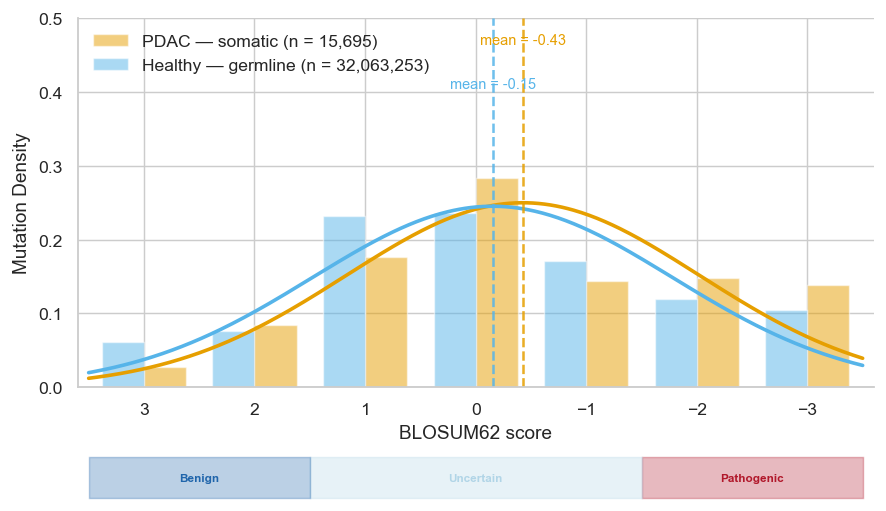

Saved to C:\Users\daane\Desktop\GitHub Repos\Bachelor_Research_Project\Figures

Note the heavy overlap and similar means — in clear contrast to the AlphaMissense
distribution in KO1, where PDAC and Healthy medians were 0.224 vs 0.076.


In [6]:
fig, ax = plot_blosum_distribution(
    scores_pdac  = tcga['blosum62_score'].drop_nulls().to_numpy(),
    scores_1000g = g1000['blosum62_score'].drop_nulls().to_numpy(),
)
fig.savefig(out_dir / 'KO3_blosum_score_distribution.pdf', dpi=300, bbox_inches='tight')
fig.savefig(out_dir / 'KO3_blosum_score_distribution.png', dpi=300, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    fig.savefig(out_dir / 'KO3_blosum_score_distribution.svg', bbox_inches='tight')
plt.show()
print('Saved to', out_dir.resolve())
print()
print('Note the heavy overlap and similar means — in clear contrast to the AlphaMissense')
print('distribution in KO1, where PDAC and Healthy medians were 0.224 vs 0.076.')

## 3. Figure 2 — Pathogenic Gene Shares (BLOSUM62, Gene-Level Median)

Each gene is categorised as benign / uncertain / pathogenic by its **median** BLOSUM62 score (`blosum62_score`, "Analysis 4b" of `09_BLOSUM.ipynb`), reproducing the gene-level categorisation logic of KO1's Figure 2 — but with BLOSUM62 instead of AlphaMissense. The resulting PDAC vs Healthy pathogenic-gene shares sit far closer together than AlphaMissense's (KO1: 25.9% vs 3.1%), directly illustrating BLOSUM62's much weaker diagnostic separation at the gene level.

In [7]:
def _cat_expr():
    return (
        pl.when(pl.col('blosum62_score') <= BL_PATH_MAX).then(pl.lit('pathogenic'))
        .when(pl.col('blosum62_score') >= BL_BENIGN_MIN).then(pl.lit('benign'))
        .otherwise(pl.lit('uncertain'))
        .alias('category')
    )


def _tally(result):
    c = {'benign': 0, 'uncertain': 0, 'pathogenic': 0}
    for row in result.iter_rows(named=True):
        c[row['category']] = int(row['count'])
    return c


def categorize_genes(subset, agg='median'):
    # Categorise each gene by its aggregated BLOSUM62 score, then tally benign/uncertain/pathogenic gene counts.
    subset = subset.filter(pl.col('blosum62_score').is_not_null())
    if len(subset) == 0:
        return {'benign': 0, 'uncertain': 0, 'pathogenic': 0}
    agg_expr = pl.col('blosum62_score').min() if agg == 'min' else pl.col('blosum62_score').median()
    scores = subset.group_by('gene_name').agg(agg_expr.alias('blosum62_score'))
    return _tally(
        scores
        .with_columns(_cat_expr())
        .group_by('category')
        .agg(pl.len().alias('count'))
    )


def plot_stacked_bar(data_dict, title, figsize=(8, 2.8), n_label='genes'):
    BAR_H = 0.6
    fig, ax = plt.subplots(figsize=figsize)
    labels = list(data_dict.keys())[::-1]
    totals = {lbl: sum(data_dict[lbl].values()) for lbl in labels}

    boundaries = {}

    for i, label in enumerate(labels):
        c     = data_dict[label]
        total = totals[label]
        if total == 0:
            ax.text(50, i, 'No data', ha='center', va='center', color='grey')
            continue
        pct_b = 100 * c['benign']     / total
        pct_u = 100 * c['uncertain']  / total
        pct_p = 100 * c['pathogenic'] / total

        ax.barh(i, pct_b,             left=0,             color=COLOR_BENIGN,    alpha=0.85, height=BAR_H)
        ax.barh(i, pct_u,             left=pct_b,         color=COLOR_UNCERTAIN, alpha=0.85, height=BAR_H)
        ax.barh(i, pct_p,             left=pct_b + pct_u, color=COLOR_PATH,      alpha=0.85, height=BAR_H)

        boundaries[i] = (pct_b, pct_b + pct_u)

        for left_offset, width, count, cat_color in [
            (0,             pct_b, c['benign'],     COLOR_BENIGN),
            (pct_b,         pct_u, c['uncertain'],  COLOR_UNCERTAIN),
            (pct_b + pct_u, pct_p, c['pathogenic'], COLOR_PATH),
        ]:
            cx = left_offset + width / 2
            if width >= 8:
                ax.text(cx, i, f'{count:,}\n({width:.1f}%)', ha='center', va='center',
                        fontsize=7, color='white', fontweight='bold', linespacing=1.25)
            elif width >= 4:
                ax.text(cx, i, f'{width:.1f}%', ha='center', va='center',
                        fontsize=7.5, color='white', fontweight='bold')
            elif width > 0:
                if i == 0:
                    ax.text(cx, i - BAR_H / 2 - 0.06, f'{count:,}\n({width:.1f}%)',
                            ha='center', va='top', fontsize=6.5, color=cat_color,
                            fontweight='bold', linespacing=1.2)
                else:
                    ax.text(cx, i + BAR_H / 2 + 0.06, f'{count:,}\n({width:.1f}%)',
                            ha='center', va='bottom', fontsize=6.5, color=cat_color,
                            fontweight='bold', linespacing=1.2)

    if len(boundaries) == 2:
        y_top_lower = BAR_H / 2
        y_bot_upper = 1 - BAR_H / 2
        all_bounds = [(0, 0), (boundaries[0][0], boundaries[1][0]),
                      (boundaries[0][1], boundaries[1][1]), (100, 100)]
        for x0, x1 in all_bounds:
            ax.plot([x0, x1], [y_top_lower, y_bot_upper],
                    color='#555555', lw=0.9, ls=':', zorder=5)

    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels([f'{lbl}\n(n = {totals[lbl]:,} {n_label})' for lbl in labels])
    ax.set_xlim(0, 100)
    ax.set_ylim(-0.85, len(labels) - 0.3)
    ax.set_title(title, fontsize=11, pad=8, fontweight='semibold')
    ax.xaxis.set_visible(False)
    legend_handles = [
        Patch(facecolor=COLOR_BENIGN,    label=f'Benign (BLOSUM62 ≥ {BL_BENIGN_MIN})'),
        Patch(facecolor=COLOR_UNCERTAIN, label='Uncertain'),
        Patch(facecolor=COLOR_PATH,      label=f'Pathogenic (BLOSUM62 ≤ {BL_PATH_MAX})'),
    ]
    ax.legend(handles=legend_handles, frameon=False, loc='upper center',
              bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=8)
    sns.despine(ax=ax, bottom=True, left=True)
    return fig, ax

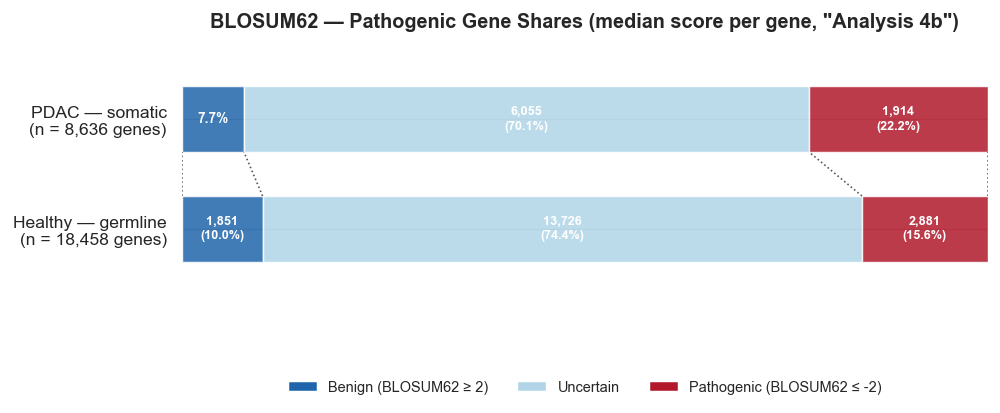

Saved to C:\Users\daane\Desktop\GitHub Repos\Bachelor_Research_Project\Figures

BLOSUM62 (median per gene): 22.2% of PDAC genes vs 15.6% of Healthy genes are pathogenic
— a gap of only 6.6 pp. AlphaMissense (KO1, Figure 2) found 25.9% vs 3.1%
— a gap of 22.8 pp — far more clearly separating PDAC from Healthy at the gene level.


In [8]:
bl_data = {
    'PDAC — somatic':     categorize_genes(tcga),
    'Healthy — germline': categorize_genes(g1000),
}

fig, ax = plot_stacked_bar(
    data_dict = bl_data,
    title     = 'BLOSUM62 — Pathogenic Gene Shares (median score per gene, "Analysis 4b")',
)

fig.savefig(out_dir / 'KO3_pathogenic_gene_share_comparison.pdf', dpi=300, bbox_inches='tight')
fig.savefig(out_dir / 'KO3_pathogenic_gene_share_comparison.png', dpi=300, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    fig.savefig(out_dir / 'KO3_pathogenic_gene_share_comparison.svg', bbox_inches='tight')
plt.show()
print('Saved to', out_dir.resolve())
print()

p_pct = 100 * bl_data['PDAC — somatic']['pathogenic']     / sum(bl_data['PDAC — somatic'].values())
h_pct = 100 * bl_data['Healthy — germline']['pathogenic'] / sum(bl_data['Healthy — germline'].values())
print(f'BLOSUM62 (median per gene): {p_pct:.1f}% of PDAC genes vs {h_pct:.1f}% of Healthy genes are pathogenic')
print(f'— a gap of only {p_pct - h_pct:.1f} pp. AlphaMissense (KO1, Figure 2) found 25.9% vs 3.1%')
print('— a gap of 22.8 pp — far more clearly separating PDAC from Healthy at the gene level.')

## 4. Figure 3 — Driver Gene BLOSUM62 Score Distributions

In [9]:
def _smooth_kde_blosum(arr, x_grid):
    # KDE with a minimum absolute bandwidth of 0.7 to fill gaps between integers —
    # Scott's rule alone gives too-narrow a bandwidth for integer-valued BLOSUM62 data.
    arr_f = arr[np.isfinite(arr)].astype(float)
    if len(arr_f) < 5:
        return None
    std_d = float(np.std(arr_f, ddof=1))
    if std_d == 0:
        return None
    scott_bw = len(arr_f) ** (-0.2)
    min_bw   = 0.7 / std_d
    kde = gaussian_kde(arr_f, bw_method=max(scott_bw, min_bw))
    return kde(x_grid)

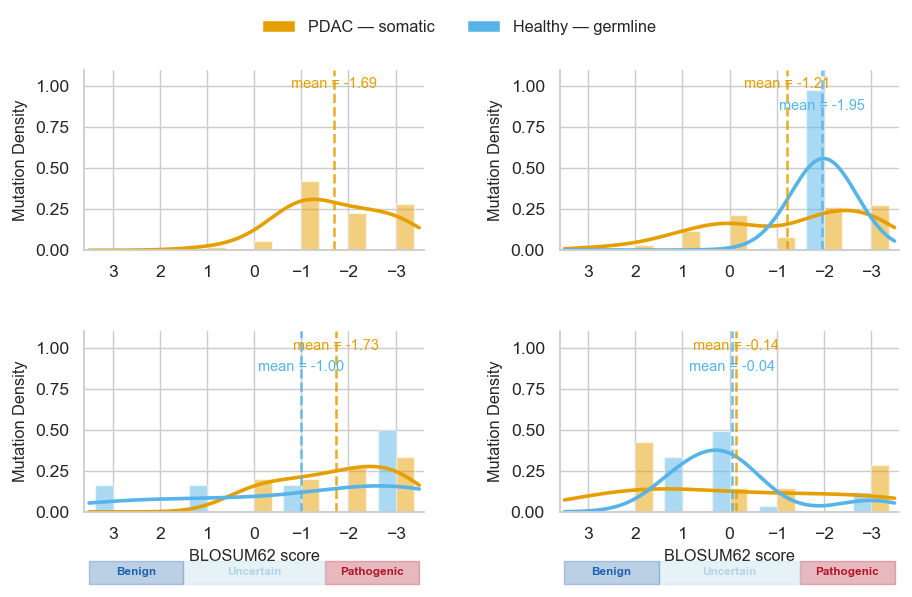

Saved to C:\Users\daane\Desktop\GitHub Repos\Bachelor_Research_Project\Figures

PDAC and Healthy BLOSUM62 distributions overlap heavily and diffusely for all four driver genes —
in clear contrast to the crisp AlphaMissense separations shown in KO2 Figure 1.


In [10]:
LAYOUT = [
    (0, 0, 'KRAS'),
    (0, 1, 'TP53'),
    (1, 0, 'SMAD4'),
    (1, 1, 'CDKN2A'),
]

fig, axes = plt.subplots(
    2, 2, figsize=(183/25.4, 5.0),
    sharex=False, sharey=True,
)
fig.subplots_adjust(
    left=0.10, right=0.97, top=0.90, bottom=0.22,
    hspace=0.45, wspace=0.40,
)

fig.legend(
    handles=[
        Patch(facecolor=COLOR_PDAC,    label='PDAC — somatic'),
        Patch(facecolor=COLOR_HEALTHY, label='Healthy — germline'),
    ],
    loc='upper center', bbox_to_anchor=(0.5, 1.00),
    ncol=2, frameon=False, fontsize=9,
)

for row, col, gene in LAYOUT:
    ax = axes[row][col]

    pdac_arr = tcga.filter(pl.col('gene_name') == gene)['blosum62_score'].drop_nulls().to_numpy()
    hlth_arr = g1000.filter(pl.col('gene_name') == gene)['blosum62_score'].drop_nulls().to_numpy()

    all_v = np.concatenate([pdac_arr, hlth_arr]).astype(int)
    bl_min_g, bl_max_g = int(all_v.min()), int(all_v.max())
    x_g = np.arange(bl_min_g, bl_max_g + 1)
    w   = 0.38
    pp  = np.array([np.sum(pdac_arr.astype(int) == v) for v in x_g], dtype=float) / max(len(pdac_arr), 1)
    ph  = np.array([np.sum(hlth_arr.astype(int) == v) for v in x_g], dtype=float) / max(len(hlth_arr), 1)

    ax.bar(x_g - w/2, pp, w, color=COLOR_PDAC,    alpha=0.50)
    ax.bar(x_g + w/2, ph, w, color=COLOR_HEALTHY, alpha=0.50)

    xs = np.linspace(-3.5, 3.5, 400)
    for arr, color in [(pdac_arr, COLOR_PDAC), (hlth_arr, COLOR_HEALTHY)]:
        ys = _smooth_kde_blosum(arr.astype(float), xs)
        if ys is not None:
            ax.plot(xs, ys, color=color, lw=2)

    ax.set_ylim(0, 1.10)
    ymax = 1.10
    for i, (arr, color) in enumerate([(pdac_arr, COLOR_PDAC), (hlth_arr, COLOR_HEALTHY)]):
        arr_f = arr.astype(float)
        arr_f = arr_f[np.isfinite(arr_f)]
        if len(arr_f) == 0:
            continue
        mean_val = float(np.mean(arr_f))
        ax.axvline(mean_val, color=color, lw=1.4, ls='--', alpha=0.85)
        ax.text(mean_val, ymax * (0.96 - i * 0.12), f'mean = {mean_val:.2f}',
                color=color, fontsize=8, ha='center', va='top')

    ax.set_xticks(range(-3, 4))
    ax.set_xlim(3.6, -3.6)   # inverted: benign left, pathogenic right
    sns.despine(ax=ax)

    ax.set_ylabel('Mutation Density', fontsize=9)
    if col == 1:
        ax.tick_params(axis='y', labelleft=True)
    if row == 1:
        ax.set_xlabel('BLOSUM62 score', fontsize=9)

    if row == 1:
        _add_blosum_colorbar(ax, y_bot=-0.40, ht=0.13, x_min=-3.5, x_max=3.5)

fig.savefig(out_dir / 'KO3_driver_gene_distributions.pdf', dpi=300, bbox_inches='tight')
fig.savefig(out_dir / 'KO3_driver_gene_distributions.png', dpi=300, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    fig.savefig(out_dir / 'KO3_driver_gene_distributions.svg', bbox_inches='tight')
plt.show()
print('Saved to', out_dir.resolve())
print()
print('PDAC and Healthy BLOSUM62 distributions overlap heavily and diffusely for all four driver genes —')
print('in clear contrast to the crisp AlphaMissense separations shown in KO2 Figure 1.')

## 5. Table — AlphaMissense vs BLOSUM62 Effect Size Comparison

Per-predictor descriptive statistics and Common Language Effect Size, computed genome-wide ("Overall") and for each of the 4 canonical driver genes.
**CLES = P[PDAC mutation more pathogenic than Healthy mutation]**, using each predictor's own pathogenicity direction:
- BLOSUM62 — lower score = more pathogenic → CLES = P[PDAC BLOSUM62 < Healthy BLOSUM62]
- AlphaMissense — higher score = more pathogenic → CLES = P[PDAC AM > Healthy AM]

`CLES_LB` is the conservative 95% confidence-interval lower bound.

In [11]:
def _cles_stats(p_arr, h_arr, lower_is_pathogenic):
    # CLES = P[PDAC mutation more pathogenic than Healthy mutation], direction-aware.
    # scipy's Mann-Whitney U always returns the count of (PDAC > Healthy) pairs regardless
    # of `alternative=`, so U / (n1 * n2) = P[PDAC > Healthy] and P[PDAC < Healthy] = 1 - U / (n1 * n2).
    n1, n2 = len(p_arr), len(h_arr)
    if n1 == 0:
        return None, None
    lb = 1.96 * np.sqrt(1 / (12 * n1))
    if n2 > 0:
        u, _ = mannwhitneyu(p_arr, h_arr, alternative='less' if lower_is_pathogenic else 'greater')
        cles = (1 - u / (n1 * n2)) if lower_is_pathogenic else (u / (n1 * n2))
    else:
        cles = 1.0   # no Healthy mutations in this gene -- maximally distinguished
    return round(cles, 4), round(cles - lb, 4)


groups = [('Overall', None)] + [(gene, gene) for gene in DRIVER_GENES]

rows = []
for label, gene in groups:
    row_filter = pl.col('blosum62_score').is_not_null()
    if gene is not None:
        row_filter &= (pl.col('gene_name') == gene)

    p_sub = tcga.filter(row_filter)
    h_sub = g1000.filter(row_filter)

    p_bl, h_bl = p_sub['blosum62_score'].to_numpy().astype(float),   h_sub['blosum62_score'].to_numpy().astype(float)
    p_am, h_am = p_sub['am_pathogenicity'].to_numpy().astype(float), h_sub['am_pathogenicity'].to_numpy().astype(float)

    cles_bl, cles_lb_bl = _cles_stats(p_bl, h_bl, lower_is_pathogenic=True)
    cles_am, cles_lb_am = _cles_stats(p_am, h_am, lower_is_pathogenic=False)

    rows.append({
        'gene':            label,
        'n_indiv_PDAC':    p_sub['sample_id'].n_unique(),
        'n_indiv_Healthy': h_sub['sample_id'].n_unique(),
        'n_mut_PDAC':      len(p_bl),
        'n_mut_Healthy':   len(h_bl),
        'CLES_BL':         cles_bl,
        'CLES_LB_BL':      cles_lb_bl,
        'CLES_AM':         cles_am,
        'CLES_LB_AM':      cles_lb_am,
    })

driver_tbl = pl.DataFrame(rows)
NUM_COLS = ['n_indiv_PDAC', 'n_indiv_Healthy', 'n_mut_PDAC', 'n_mut_Healthy',
            'CLES_BL', 'CLES_LB_BL', 'CLES_AM', 'CLES_LB_AM']

(
    GT(driver_tbl, rowname_col='gene')
    .tab_header(
        title    = md('**AlphaMissense vs BLOSUM62 — Effect Size Comparison (PDAC vs Healthy)**'),
        subtitle = md('CLES = P[PDAC mutation more pathogenic than Healthy] · CLES_LB = conservative 95% lower bound · '
                      '*Overall* = whole population (genome-wide)'),
    )
    .tab_spanner(label='# Individuals',  columns=['n_indiv_PDAC', 'n_indiv_Healthy'])
    .tab_spanner(label='# Mutations',    columns=['n_mut_PDAC',   'n_mut_Healthy'])
    .tab_spanner(label='BLOSUM62',       columns=['CLES_BL', 'CLES_LB_BL'])
    .tab_spanner(label='AlphaMissense',  columns=['CLES_AM', 'CLES_LB_AM'])
    .cols_label(
        n_indiv_PDAC='PDAC', n_indiv_Healthy='Healthy',
        n_mut_PDAC='PDAC',   n_mut_Healthy='Healthy',
        CLES_BL='CLES',    CLES_LB_BL='CLES_LB',
        CLES_AM='CLES',    CLES_LB_AM='CLES_LB',
    )
    .cols_align(align='right', columns=NUM_COLS)
    .fmt_integer(columns=['n_indiv_PDAC', 'n_indiv_Healthy', 'n_mut_PDAC', 'n_mut_Healthy'])
    .fmt_number(columns=['CLES_BL', 'CLES_LB_BL', 'CLES_AM', 'CLES_LB_AM'], decimals=3)
    .tab_style(style=style.text(weight='bold'),                                      locations=loc.body(rows=[0]))
    .tab_style(style=style.borders(sides='bottom', color='#aaaaaa', weight='1.5px'), locations=loc.body(rows=[0]))
    .tab_style(style=style.borders(sides='left', color='#cccccc', weight='1px'),     locations=loc.body(columns=['CLES_AM']))
    .tab_options(table_font_size='12px', column_labels_font_weight='bold', heading_padding='8px', data_row_padding='5px')
    .tab_source_note(source_note=md(
        '_BLOSUM62: lower score = more pathogenic → CLES = P[PDAC BLOSUM62 < Healthy BLOSUM62]. '
        'AlphaMissense: higher score = more pathogenic → CLES = P[PDAC AM > Healthy AM]._'
    ))
)

GT(_tbl_data=shape: (5, 9)
┌─────────┬────────────┬────────────┬────────────┬───┬─────────┬────────────┬─────────┬────────────┐
│ gene    ┆ n_indiv_PD ┆ n_indiv_He ┆ n_mut_PDAC ┆ … ┆ CLES_BL ┆ CLES_LB_BL ┆ CLES_AM ┆ CLES_LB_AM │
│ ---     ┆ AC         ┆ althy      ┆ ---        ┆   ┆ ---     ┆ ---        ┆ ---     ┆ ---        │
│ str     ┆ ---        ┆ ---        ┆ i64        ┆   ┆ f64     ┆ f64        ┆ f64     ┆ f64        │
│         ┆ i64        ┆ i64        ┆            ┆   ┆         ┆            ┆         ┆            │
╞═════════╪════════════╪════════════╪════════════╪═══╪═════════╪════════════╪═════════╪════════════╡
│ Overall ┆ 168        ┆ 3202       ┆ 15695      ┆ … ┆ 0.5458  ┆ 0.5413     ┆ 0.8298  ┆ 0.8253     │
│ KRAS    ┆ 106        ┆ 0          ┆ 107        ┆ … ┆ 1.0     ┆ 0.9453     ┆ 1.0     ┆ 0.9453     │
│ TP53    ┆ 61         ┆ 2494       ┆ 61         ┆ … ┆ 0.4165  ┆ 0.3441     ┆ 0.9833  ┆ 0.9108     │
│ SMAD4   ┆ 15         ┆ 12         ┆ 15         ┆ … ┆ 0.5333  ┆ 0.3872     ┆ 1.0     ┆ 0.8539     │
│ CDKN2A  ┆ 7          ┆ 155        ┆ 7          ┆ … ┆ 0.4785  ┆ 0.2646     ┆ 0.9689  ┆ 0.755      │
└─────────┴────────────┴────────────┴────────────┴───┴─────────┴────────────┴─────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x0000017313052270>, _boxhead=Boxhead([ColInfo(var='gene', type=<ColInfoTypeEnum.stub: 2>, column_label='gene', column_align='left', column_width=None), ColInfo(var='n_indiv_PDAC', type=<ColInfoTypeEnum.default: 1>, column_label='PDAC', column_align='right', column_width=None), ColInfo(var='n_indiv_Healthy', type=<ColInfoTypeEnum.default: 1>, column_label='Healthy', column_align='right', column_width=None), ColInfo(var='n_mut_PDAC', type=<ColInfoTypeEnum.default: 1>, column_label='PDAC', column_align='right', column_width=None), ColInfo(var='n_mut_Healthy', type=<ColInfoTypeEnum.default: 1>, column_label='Healthy', column_align='right', column_width=None), ColInfo(var='CLES_BL', type=<ColInfoTypeEnum.default: 1>, column_label='CLES', column_align='right', column_width=None), ColInfo(var='CLES_LB_BL', type=<ColInfoTypeEnum.default: 1>, column_label='CLES_LB', column_align='right', column_width=None), ColInfo(var='CLES_AM', type=<ColInfoTypeEnum.default: 1>, column_label='CLES', column_align='right', column_width=None), ColInfo(var='CLES_LB_AM', type=<ColInfoTypeEnum.default: 1>, column_label='CLES_LB', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x0000017313051FD0>, _spanners=Spanners([SpannerInfo(spanner_id='# Individuals', spanner_level=0, spanner_label='# Individuals', spanner_units=None, spanner_pattern=None, vars=['n_indiv_PDAC', 'n_indiv_Healthy'], built=None), SpannerInfo(spanner_id='# Mutations', spanner_level=0, spanner_label='# Mutations', spanner_units=None, spanner_pattern=None, vars=['n_mut_PDAC', 'n_mut_Healthy'], built=None), SpannerInfo(spanner_id='BLOSUM62', spanner_level=0, spanner_label='BLOSUM62', spanner_units=None, spanner_pattern=None, vars=['CLES_BL', 'CLES_LB_BL'], built=None), SpannerInfo(spanner_id='AlphaMissense', spanner_level=0, spanner_label='AlphaMissense', spanner_units=None, spanner_pattern=None, vars=['CLES_AM', 'CLES_LB_AM'], built=None)]), _heading=Heading(title=Md(text='**AlphaMissense vs BLOSUM62 — Effect Size Comparison (PDAC vs Healthy)**'), subtitle=Md(text='CLES = P[PDAC mutation more pathogenic than Healthy] · CLES_LB = conservative 95% lower bound · *Overall* = whole population (genome-wide)'), preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x0000017313052660>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x0000017313439E50>, _source_notes=[Md(text='_BLOSUM62: lower score = more pathogenic → CLES = P[PDAC BLOSUM62 < Healthy BLOSUM62]. AlphaMissense: higher score = more pathogenic → CLES = P[PDAC AM > Healthy AM]._')], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=[0], mask=None), grpname=None, c